

| Bước | Nhiệm vụ | 
|---|---|
| 2.4.1 | Nạp dữ liệu đã làm sạch |
| 2.4.2 | Chọn thuộc tính khai phá | 
| 2.4.3 | Giảm bớt thuộc tính (lọc kỹ năng hiếm) | 
| 2.4.4 | One-hot encoding |
| 2.4.5 | Khai phá tập phổ biến bằng Apriori |
| 2.4.6 | Khai phá bằng FP-Growth & so sánh |
| 2.4.7 | Sinh luật kết hợp |
| 2.4.8 | Lọc luật |
| 2.4.9 | Xem top luật | 
| 2.4.10 | Kiểm tra luật cụ thể theo chủ đề |
| 2.5.11 | Phát hiện luật gây nhiễu | 
| 2.5.12 | Trực quan hóa | 

# BƯỚC 2.4.1 : NẠP DỮ LIỆU VÀO 

In [2]:
import os
import time
import json
import warnings

warnings.filterwarnings('ignore')
import pandas as pd 
from IPython.display import display
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import (
    apriori,
    fpgrowth,
    association_rules
)

# Đọc dữ liệu đã qua bước Cleaning
input_file = '../buoc2.1_2.2/data/processed/clean_data_processed.csv'

if not os.path.exists(input_file):
    raise FileNotFoundError(f"Không tìm thấy file: {input_file}")

df = pd.read_csv(input_file, encoding='utf-8')

# Kiểm tra dữ liệu
print("File:", input_file)
print("Số bản ghi:", len(df))
print("Số cột:", df.shape[1])
print("Danh sách cột:", df.columns.tolist())

display(df.head())



File: ../buoc2.1_2.2/data/processed/clean_data_processed.csv
Số bản ghi: 3135
Số cột: 47
Danh sách cột: ['job_uid', 'job_group_id', 'source', 'URL_Goc', 'Timestamp', 'posted_date', 'posted_date_source', 'title', 'company', 'it_decision_source', 'title_role', 'work_mode_source', 'exp_min_years', 'exp_max_years', 'exp_source', 'Luong_Min', 'Luong_Max', 'Luong_TB', 'salary_status', 'salary_currency_orig', 'salary_period_assumed', 'salary_source', 'languages', 'benefits', 'jd_chars', 'scope_status', 'salary_invalid_bounds', 'salary_status_conflict', 'salary_eda_eligible', 'salary_eda_conservative', 'cities_clean', 'n_cities', 'work_mode_clean', 'experience_review', 'experience_group', 'seniority_clean', 'seniority_basis', 'intern_flag_review', 'description_clean', 'has_jd_clean', 'tech_list', 'keywords_list', 'skills', 'broad_concepts', 'application_domains', 'n_skills', 'text_for_tfidf']


,job_uid,job_group_id,source,URL_Goc,Timestamp,posted_date,posted_date_source,title,company,it_decision_source,...,intern_flag_review,description_clean,has_jd_clean,tech_list,keywords_list,skills,broad_concepts,application_domains,n_skills,text_for_tfidf
0,itviec-b9bccb83ab,g38788d35,itviec,https://itviec.com/it-jobs/manual-quality-assu...,2026-11-17T18:09:16+07:00,11/10/2026,field,Manual Quality Assurance (Senior/Lead),VinSmart Future,filter,...,False,Top 3 Reasons To Join Us Competitive Salary & ...,True,"[""Jira"", ""SQL""]","[""Azure"", ""DevOps""]","[""Azure"", ""DevOps"", ""Jira"", ""SQL""]",[],[],4,reasons join competitive salary benefits train...
1,itviec-ea14bd1d88,gb2b041c2,itviec,https://itviec.com/it-jobs/senior-data-scienti...,2026-11-17T18:09:16+07:00,10/27/2026,field,Senior Data Scientist - GSM Platform,VinSmart Future,filter,...,False,Top 3 Reasons To Join Us Competitive Salary & ...,True,"[""Python"", ""SQL"", ""Spark""]","[""Computer Vision"", ""Machine Learning""]","[""Computer Vision"", ""Machine Learning"", ""Pytho...",[],[],5,reasons join competitive salary benefits train...
2,itviec-99df719b7e,gb9e2c43d,itviec,https://itviec.com/it-jobs/japanese-tester-qa-...,2026-11-17T18:09:16+07:00,11/10/2026,field,Japanese Tester (QA/QC),Kobo Asia,filter,...,False,Top 3 Reasons To Join Us Cùng nhau thử thách v...,True,"[""Git"", ""Jira"", ""SQL"", ""SQL Server""]","[""AI""]","[""Git"", ""Jira"", ""SQL"", ""SQL Server""]","[""AI""]",[],4,reasons join cùng nhau thử thách kĩ thuật mới ...
3,itviec-8f816367b4,g0774918e,itviec,https://itviec.com/it-jobs/senior-application-...,2026-11-17T18:09:16+07:00,11/7/2026,field,Senior Application Operations Engineer (SysOps),Ngân hàng TMCP Tiên Phong | TPBank,filter,...,False,Top 3 Reasons To Join Us Thưởng dự án và thưởn...,True,"[""Kubernetes"", ""Linux""]","[""DevOps""]","[""DevOps"", ""Kubernetes"", ""Linux""]",[],[],3,reasons join thưởng dự án thưởng cuối năm cao ...
4,itviec-2825747e21,gc0b05eb6,itviec,https://itviec.com/it-jobs/ai-engineer-kobo-as...,2026-11-17T18:09:16+07:00,11/10/2026,field,AI Engineer,Kobo Asia,filter,...,False,Top 3 Reasons To Join Us Cùng nhau thử thách v...,True,"["".NET"", ""C#"", ""Docker"", ""Git"", ""GitHub"", ""Git...","[""AI"", ""AWS"", ""CI/CD"", ""DevOps"", ""LLM"", ""Unit ...","["".NET"", ""AWS"", ""C#"", ""CI/CD"", ""DevOps"", ""Dock...","[""AI""]",[],14,reasons join cùng nhau thử thách kĩ thuật mới ...


# Bước 2.4.2 : CHỌN THUỘC TÍNH KHAI PHÁ

In [3]:
import pandas as pd
from IPython.display import display

# Các cột thông tin muốn hiển thị
cols = [
    'title',
    'tech_list',
    'keywords_list',
    'skills',
    'broad_concepts',
    'application_domains',
    'languages',
    'benefits'
]

# Chỉ lấy những cột tồn tại
selected_cols = [c for c in cols if c in df.columns]

# Tạo bảng hiển thị, không thay đổi df gốc
view_df = df[selected_cols].head(10).copy()

# Chuyển danh sách thành chuỗi dễ đọc
def format_value(x):
    if isinstance(x, (list, tuple, set)):
        return ", ".join(map(str, x)) if x else "—"
    if pd.isna(x) if not isinstance(x, (list, tuple, set)) else False:
        return "—"
    return str(x)

for col in view_df.columns:
    view_df[col] = view_df[col].apply(format_value)

# Hiển thị bảng
display(
    view_df.style
    .hide(axis="index")
    .set_properties(**{
        "background-color": "#141414",
        "color": "#D0D0D0",
        "border": "1px solid #303030",
        "padding": "12px",
        "text-align": "left",
        "white-space": "normal",
        "min-width": "130px",
        "max-width": "300px",
        "font-size": "13px"
    })
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#292929"),
                ("color", "#FFFFFF"),
                ("padding", "14px"),
                ("text-align", "center"),
                ("font-weight", "bold"),
                ("border-bottom", "2px solid #555555")
            ]
        },
        {
            "selector": "tbody tr:nth-child(even)",
            "props": [("background-color", "#242424")]
        },
        {
            "selector": "tbody tr:nth-child(odd)",
            "props": [("background-color", "#141414")]
        },
        {
            "selector": "table",
            "props": [
                ("border-collapse", "collapse"),
                ("width", "100%"),
                ("table-layout", "auto")
            ]
        }
    ])
)

title,tech_list,keywords_list,skills,broad_concepts,application_domains,languages,benefits
Manual Quality Assurance (Senior/Lead),"[""Jira"", ""SQL""]","[""Azure"", ""DevOps""]","[""Azure"", ""DevOps"", ""Jira"", ""SQL""]",[],[],[],"[""Thưởng (KPI/dự án/lễ tết)"", ""BHXH / chế độ theo luật"", ""Du lịch / team building"", ""Đào tạo / chứng chỉ"", ""Nghỉ phép có lương"", ""Làm việc linh hoạt / hybrid"", ""Phụ cấp / ăn trưa / đưa đón""]"
Senior Data Scientist - GSM Platform,"[""Python"", ""SQL"", ""Spark""]","[""Computer Vision"", ""Machine Learning""]","[""Computer Vision"", ""Machine Learning"", ""Python"", ""SQL"", ""Spark""]",[],[],[],"[""Thưởng (KPI/dự án/lễ tết)"", ""BHXH / chế độ theo luật"", ""Du lịch / team building"", ""Đào tạo / chứng chỉ"", ""Nghỉ phép có lương"", ""Làm việc linh hoạt / hybrid"", ""Phụ cấp / ăn trưa / đưa đón""]"
Japanese Tester (QA/QC),"[""Git"", ""Jira"", ""SQL"", ""SQL Server""]","[""AI""]","[""Git"", ""Jira"", ""SQL"", ""SQL Server""]","[""AI""]",[],"[""English"", ""Japanese""]","[""Thưởng (KPI/dự án/lễ tết)"", ""Xét tăng lương định kỳ"", ""Du lịch / team building"", ""Đào tạo / chứng chỉ"", ""Nghỉ phép có lương"", ""Làm việc linh hoạt / hybrid"", ""Phụ cấp / ăn trưa / đưa đón""]"
Senior Application Operations Engineer (SysOps),"[""Kubernetes"", ""Linux""]","[""DevOps""]","[""DevOps"", ""Kubernetes"", ""Linux""]",[],[],"[""English""]","[""Thưởng (KPI/dự án/lễ tết)"", ""Du lịch / team building"", ""Nghỉ phép có lương"", ""Phụ cấp / ăn trưa / đưa đón""]"
AI Engineer,"["".NET"", ""C#"", ""Docker"", ""Git"", ""GitHub"", ""GitHub Actions"", ""GitLab"", ""Jenkins"", ""Playwright""]","[""AI"", ""AWS"", ""CI/CD"", ""DevOps"", ""LLM"", ""Unit Test""]","["".NET"", ""AWS"", ""C#"", ""CI/CD"", ""DevOps"", ""Docker"", ""Git"", ""GitHub"", ""GitHub Actions"", ""GitLab"", ""Jenkins"", ""LLM"", ""Playwright"", ""Unit Test""]","[""AI""]",[],"[""Japanese""]","[""Thưởng (KPI/dự án/lễ tết)"", ""Xét tăng lương định kỳ"", ""Du lịch / team building"", ""Đào tạo / chứng chỉ"", ""Nghỉ phép có lương"", ""Làm việc linh hoạt / hybrid"", ""Phụ cấp / ăn trưa / đưa đón""]"
System Designer - BrSE (Japanese speaking),"[""C#"", ""JavaScript""]","[""Design Patterns""]","[""C#"", ""Design Patterns"", ""JavaScript""]",[],[],"[""Japanese""]","[""Thưởng (KPI/dự án/lễ tết)"", ""Xét tăng lương định kỳ"", ""Du lịch / team building"", ""Đào tạo / chứng chỉ"", ""Nghỉ phép có lương"", ""Làm việc linh hoạt / hybrid"", ""Phụ cấp / ăn trưa / đưa đón""]"
"Staff Mobile Engineer (Android/iOS, Fluent in English)","[""Android"", ""C++"", ""Flutter"", ""Java"", ""JavaScript"", ""Kotlin"", ""Objective-C"", ""React Native"", ""Swift"", ""iOS""]","[""Agile"", ""CI/CD"", ""Cybersecurity"", ""Design Patterns""]","[""Agile"", ""Android"", ""C++"", ""CI/CD"", ""Cybersecurity"", ""Design Patterns"", ""Flutter"", ""Java"", ""JavaScript"", ""Kotlin"", ""Objective-C"", ""React Native"", ""Swift"", ""iOS""]",[],[],[],"[""Lương tháng 13"", ""Thưởng (KPI/dự án/lễ tết)"", ""Xét tăng lương định kỳ"", ""Bảo hiểm / chăm sóc sức khỏe"", ""Du lịch / team building"", ""Đào tạo / chứng chỉ"", ""Nghỉ phép có lương"", ""Làm việc linh hoạt / hybrid"", ""Phụ cấp / ăn trưa / đưa đón""]"
Middle/Senior Backend Engineer (Java),"[""Elasticsearch"", ""Java"", ""Kafka"", ""MongoDB"", ""MySQL"", ""PostgreSQL"", ""REST API"", ""Redis"", ""SQL"", ""Spring"", ""gRPC""]","[""AI"", ""Microservices"", ""OOP""]","[""Elasticsearch"", ""Java"", ""Kafka"", ""Microservices"", ""MongoDB"", ""MySQL"", ""OOP"", ""PostgreSQL"", ""REST API"", ""Redis"", ""SQL"", ""Spring"", ""gRPC""]","[""AI""]",[],[],"[""Thưởng (KPI/dự án/lễ tết)"", ""BHXH / chế độ theo luật"", ""Du lịch / team building"", ""Đào tạo / chứng chỉ"", ""Nghỉ phép có lương"", ""Làm việc linh hoạt / hybrid"", ""Phụ cấp / ăn trưa / đưa đón""]"
Business Analyst – Proprietary Trading Systems,"[""BPMN"", ""Jira"", ""Python"", ""SQL"", ""UML""]","[""AI"", ""Agile"", ""Fintech"", ""Scrum""]","[""Agile"", ""BPMN"", ""Jira"", ""Python"", ""SQL""

#  BƯỚC 2.4.3 LÀM GIẢM BỚT NHỮNG THUỘC TÍNH CÓ

In [4]:
MIN_COUNT = 30

def to_list(x):
    if isinstance(x, list):
        return x
    try:
        return json.loads(x) if isinstance(x, str) else []
    except Exception:
        return []

skill_lists = df['skills'].apply(to_list).apply(lambda l: sorted({s.strip().lower() for s in l}))

cnt = Counter(s for l in skill_lists for s in l)
keep = {s for s, n in cnt.items() if n >= MIN_COUNT}

transactions = [[s for s in l if s in keep] for l in skill_lists]
transactions = [t for t in transactions if len(t) >= 2]

print("Số kỹ năng khác nhau:", len(cnt), "| giữ lại:", len(keep))
print("Số transaction:", len(transactions))
print("Ví dụ:", transactions[:3])

Số kỹ năng khác nhau: 157 | giữ lại: 121
Số transaction: 2552
Ví dụ: [['azure', 'devops', 'jira', 'sql'], ['computer vision', 'machine learning', 'python', 'spark', 'sql'], ['git', 'jira', 'sql', 'sql server']]


###  Phân tích Bước 2.4.3: Giảm bớt thuộc tính (lọc kỹ năng hiếm)

**Vì sao làm bước này?**
Có hai lý do:
1. **Độ tin cậy thống kê:** một kỹ năng chỉ xuất hiện vài lần thì luật chứa nó không đáng tin (có thể chỉ là trùng hợp).
2. **Hiệu năng:** càng nhiều mục thì số tổ hợp cần xét càng bùng nổ (với 157 mục, số tập con có thể lên đến hàng tỷ).

**Đã làm gì? (theo thứ tự trong code)**
1. Hàm `to_list` đọc cột `skills`. Cột này lưu dạng chuỗi JSON nên cần `json.loads` để thành danh sách thật; lỗi thì trả về danh sách rỗng.
2. **Chuẩn hóa:** `strip()` và `lower()` để "Python" và "python " được tính là một; dùng `set` để loại kỹ năng trùng trong cùng một tin.
3. Đếm số tin chứa từng kỹ năng bằng `Counter`, **giữ kỹ năng xuất hiện ≥ 30 lần** (`MIN_COUNT = 30`).
4. **Bỏ các tin còn dưới 2 kỹ năng**, vì một giỏ chỉ có 1 món thì không thể tạo ra luật "A ⇒ B".

**Kết quả:**
| Chỉ số | Giá trị |
|---|---|
| Số kỹ năng ban đầu | 157 |
| Số kỹ năng giữ lại | **121** (loại 36 kỹ năng hiếm) |
| Số transaction | **2.552** (từ 3.135 tin, bỏ khoảng 583 tin quá ít kỹ năng) |

Ví dụ một transaction: `['azure', 'devops', 'jira', 'sql']`, đúng dạng "giỏ hàng kỹ năng".

**Đánh đổi cần lưu ý:** `MIN_COUNT = 30` là lựa chọn chủ quan. Đặt thấp hơn thì giữ được kỹ năng ngách nhưng luật nhiễu hơn; đặt cao hơn thì luật chắc hơn nhưng mất các kỹ năng chuyên biệt. Mức 30 (~1% số tin) là điểm cân bằng hợp lý.

** Chuyển sang bước tiếp theo:** Dữ liệu giờ là danh sách các danh sách, nhưng thư viện khai phá cần một *bảng số liệu*. Bước tiếp theo là chuyển sang dạng one-hot.

# BƯỚC 2.4.4 : CHUYỂN TRANSACTIONS THÀNH ONE HOT ENCODING

In [5]:
te = TransactionEncoder()
onehot = pd.DataFrame(te.fit(transactions).transform(transactions), columns=te.columns_)
print(onehot.shape)
display(onehot.iloc[:5, :30])
#top 20 từ khóa gặp nhiều nhất
print("Top 20 từ khóa gặp nhiều nhất:")
top = onehot.mean().sort_values(ascending=False).head(20).index
display(onehot[top].head(10))

(2552, 121)


,.net,active directory,agile,airflow,android,angular,ansible,appium,asp.net,aws,...,crm,css,cybersecurity,cypress,databricks,deep learning,design patterns,devops,django,docker
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
4,True,False,False,False,False,False,False,False,False,True,...,False,False,False,False,False,False,False,True,False,True


Top 20 từ khóa gặp nhiều nhất:


,python,sql,ci/cd,agile,docker,aws,java,git,linux,devops,kubernetes,azure,rest api,scrum,microservices,postgresql,llm,javascript,google cloud,jira
0,False,True,False,False,False,False,False,False,False,True,False,True,False,False,False,False,False,False,False,True
1,True,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,True,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,True
3,False,False,False,False,False,False,False,False,True,True,True,False,False,False,False,False,False,False,False,False
4,False,False,True,False,True,True,False,True,False,True,False,False,False,False,False,False,True,False,False,False
5,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False
6,False,False,True,True,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False,False
7,False,True,False,False,False,False,True,False,False,False,False,False,True,False,True,True,False,False,False,False
8,True,True,False,True,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,True
9,False,False,True,True,False,False,False,False,False,False,True,False,True,True,True,True,True,False,True,False


###  Phân tích Bước 2.4.4: Chuyển transaction thành One-Hot Encoding

**Vì sao làm bước này?**
Thuật toán Apriori/FP-Growth của `mlxtend` không đọc được danh sách thô. Nó cần một ma trận mà mỗi **hàng là một tin tuyển dụng**, mỗi **cột là một kỹ năng**, và ô nhận `True` nếu tin đó yêu cầu kỹ năng ấy.

**Ví dụ minh họa:**
| | python | sql | docker |
|---|:-:|:-:|:-:|
| Tin 1 `[python, sql]` | True | True | False |
| Tin 2 `[docker, sql]` | False | True | True |

**Kết quả:**
- Ma trận có kích thước **2.552 × 121**.
- Bảng xem trước cho thấy ma trận rất **thưa** (đa số ô là `False`), vì mỗi tin chỉ yêu cầu vài kỹ năng trong tổng số 121. Đây là đặc điểm bình thường của dữ liệu giỏ hàng.
- Khi lấy trung bình cột (`onehot.mean()`), ta thu được **tỷ lệ xuất hiện** của từng kỹ năng. Top 10: **python, sql, ci/cd, agile, docker, aws, java, git, linux, devops**.

**Ý nghĩa:** Danh sách top phản ánh đúng thực tế ngành. Ngoài ngôn ngữ lập trình (Python, Java, SQL) còn có nhóm quy trình (Agile, CI/CD) và hạ tầng (Docker, AWS, Linux), cho thấy tin tuyển dụng IT đòi hỏi cả kỹ năng lập trình lẫn vận hành.

** Chuyển sang bước tiếp theo:** Có ma trận rồi, ta bắt đầu tìm **các tập kỹ năng thường xuất hiện cùng nhau**, tức tập phổ biến, bằng thuật toán Apriori.

# BƯỚC 2.4.5 : APRIORI

In [6]:
MIN_SUP = 0.03

t0 = time.time()
fi_ap = apriori(onehot, min_support=MIN_SUP, use_colnames=True, max_len=4)
t_ap = time.time() - t0

fi_ap['len'] = fi_ap['itemsets'].apply(len)
print(f"Apriori: {len(fi_ap)} itemset, {t_ap:.3f}s")
print(fi_ap['len'].value_counts().sort_index())
display(fi_ap.sort_values('support', ascending=False).head(10))

Apriori: 769 itemset, 0.046s
len
1     77
2    328
3    285
4     79
Name: count, dtype: int64


,support,itemsets,len
57,0.351097,frozenset({python}),1
69,0.308777,frozenset({sql}),1
12,0.280172,frozenset({ci/cd}),1
1,0.230408,frozenset({agile}),1
19,0.211207,frozenset({docker}),1
6,0.209639,frozenset({aws}),1
34,0.201411,frozenset({java}),1
25,0.192790,frozenset({git}),1
40,0.190439,frozenset({linux}),1
18,0.186912,frozenset({devops}),1


###  Phân tích Bước 2.4.5: Khai phá tập phổ biến bằng Apriori

**Vì sao làm bước này?**
Trước khi nói "A kéo theo B", ta phải biết **A và B có xuất hiện cùng nhau đủ nhiều hay không**. Bước này tìm mọi tổ hợp kỹ năng đạt ngưỡng đó, gọi là *tập phổ biến* (frequent itemsets).

**Khái niệm chính, Support:**
> Support(X) = (số tin chứa tất cả kỹ năng trong X) ÷ (tổng số tin)

**Tham số và lý do chọn:**
- `min_support = 0.03`: tổ hợp phải xuất hiện trong ít nhất ~3% số tin (≈ 77 tin trên 2.552). Thấp hơn thì nhiễu, cao hơn thì mất các cụm kỹ năng chuyên biệt.
- `max_len = 4`: chỉ xét tối đa 4 kỹ năng một tổ hợp. Luật quá dài khó đọc và ít ứng dụng thực tế.

**Nguyên lý Apriori:** nếu một tập không phổ biến thì mọi tập chứa nó cũng không phổ biến. Nhờ vậy thuật toán cắt tỉa được rất nhiều tổ hợp ngay từ đầu.

**Kết quả:** tìm được **769 tập phổ biến**:

| Kích thước | Số tập |
|:-:|:-:|
| 1 kỹ năng | 77 |
| 2 kỹ năng | 328 |
| 3 kỹ năng | 285 |
| 4 kỹ năng | 79 |

Số tập tăng lên ở kích thước 2 rồi giảm dần: tổ hợp càng dài càng hiếm đạt ngưỡng 3%. Đứng đầu là **Python (35,1%)** và **SQL (30,9%)**, rồi CI/CD (28,0%), Agile (23,0%), Docker (21,1%).

** Chuyển sang bước tiếp theo:** Để chắc kết quả này đáng tin, ta kiểm chứng bằng một thuật toán khác là FP-Growth. Nếu hai thuật toán cho cùng đáp án thì có thể yên tâm.

# BƯỚC 2.4.6 : FP GROWTH

In [7]:
t0 = time.time()
fi_fp = fpgrowth(onehot, min_support=MIN_SUP, use_colnames=True, max_len=4)
t_fp = time.time() - t0

print(f"FP-Growth: {len(fi_fp)} itemset, {t_fp:.3f}s")
print("Cùng tập itemset:", set(fi_ap['itemsets']) == set(fi_fp['itemsets']))
print("so sánh tốc độ giữa Apriori và FP-Growth:")
print(f"Apriori {t_ap:.3f}s | FP-Growth {t_fp:.3f}s")

FP-Growth: 769 itemset, 0.093s
Cùng tập itemset: True
so sánh tốc độ giữa Apriori và FP-Growth:
Apriori 0.046s | FP-Growth 0.093s


###  Phân tích Bước 2.4.6: Khai phá bằng FP-Growth và so sánh với Apriori

**Vì sao làm bước này?**
Có hai mục đích: (1) **kiểm chứng chéo** tính đúng đắn của kết quả, (2) **so sánh hiệu năng** hai thuật toán.

**Khác biệt về cách làm:**
| | Apriori | FP-Growth |
|---|---|---|
| Cách tiếp cận | Sinh tập ứng viên rồi đếm lại dữ liệu nhiều lần | Nén dữ liệu vào cây FP-tree, khai phá trực tiếp trên cây |
| Điểm mạnh | Đơn giản, dễ hiểu | Không sinh ứng viên, thường nhanh hơn trên dữ liệu lớn |

**Kết quả:**
- Hai thuật toán cho **cùng 769 itemset** (`set(...) == set(...)` trả về `True`), nên kết quả đúng và nhất quán.
- Thời gian: **Apriori 0,033s**, **FP-Growth 0,087s**.

**Vì sao Apriori lại nhanh hơn, ngược với lý thuyết?**
Dữ liệu ở đây khá nhỏ (2.552 × 121) và đã giới hạn `max_len = 4`, nên Apriori ít phải duyệt. Trong khi đó FP-Growth mất thời gian dựng cây FP-tree, một chi phí cố định không đáng khi dữ liệu nhỏ. FP-Growth chỉ phát huy thế mạnh khi dữ liệu lớn, support thấp hoặc tổ hợp dài. Thời gian cỡ phần trăm giây cũng dễ dao động theo máy nên không nên kết luận quá mạnh.

** Chuyển sang bước tiếp theo:** Tập phổ biến mới chỉ cho biết "cái gì đi cùng nhau", chưa cho biết **chiều** và **độ mạnh** của mối quan hệ. Bước tiếp theo là biến chúng thành các luật "A ⇒ B".

# BƯỚC 2.4.7 : SINH LUẬT

In [8]:
try:
    rules = association_rules(fi_fp, metric='confidence', min_threshold=0.0)
except TypeError:   # mlxtend bản mới yêu cầu num_itemsets
    rules = association_rules(fi_fp, num_itemsets=len(onehot), metric='confidence', min_threshold=0.0)

rules['rule'] = rules['antecedents'].apply(lambda x: ', '.join(sorted(x))).radd('{') + '} => {' + \
                rules['consequents'].apply(lambda x: ', '.join(sorted(x))) + '}'

print("Số luật thô:", len(rules))
display(rules[['rule', 'support', 'confidence', 'lift', 'conviction']].head())

Số luật thô: 3472


,rule,support,confidence,lift,conviction
0,{python} => {sql},0.129310,0.368304,1.192780,1.094232
1,{sql} => {python},0.129310,0.418782,1.192780,1.116453
2,{sql} => {devops},0.049373,0.159898,0.855474,0.967845
3,{devops} => {sql},0.049373,0.264151,0.855474,0.939354
4,{linux} => {devops},0.057210,0.300412,1.607233,1.162237


###  Phân tích Bước 2.4.7: Sinh luật kết hợp

**Vì sao làm bước này?**
Tập `{docker, kubernetes}` phổ biến chỉ cho biết hai kỹ năng hay đi cùng nhau. Ta cần luật có hướng, ví dụ `docker ⇒ kubernetes`, để trả lời: *"Nếu tin yêu cầu Docker thì khả năng có Kubernetes là bao nhiêu?"*

**Các thước đo dùng để đánh giá luật A ⇒ B:**
| Thước đo | Ý nghĩa | Cách đọc |
|---|---|---|
| **Support** | Tỷ lệ tin chứa cả A và B | Luật phổ biến đến mức nào |
| **Confidence** | P(B \| A), trong các tin có A thì bao nhiêu % có B | Độ chắc chắn của luật |
| **Lift** | Confidence ÷ Support(B) | **> 1**: A và B kéo nhau lên; **= 1**: độc lập; **< 1**: loại trừ nhau |
| **Conviction** | Mức luật "sai" ít hơn so với ngẫu nhiên | Càng cao càng đáng tin; **∞** khi confidence = 100% |

Code dùng `min_threshold = 0.0` có chủ đích: **giữ lại tất cả** để bước sau tự lọc, và để ta còn quan sát cả các luật yếu hoặc ngược chiều. Đoạn `try/except` xử lý khác biệt giữa các phiên bản `mlxtend` (bản mới yêu cầu tham số `num_itemsets`).

**Kết quả:** sinh ra **3.472 luật thô**. Năm dòng đầu minh họa rất rõ vì sao cần lọc:
- `{sql} ⇒ {python}`: confidence 41,9% nhưng **lift chỉ 1,19**, liên kết yếu.
- `{sql} ⇒ {devops}`: **lift 0,86 < 1**, SQL và DevOps thậm chí ít đi cùng nhau hơn mức ngẫu nhiên.
- `{linux} ⇒ {devops}`: lift 1,61, liên kết khá rõ, hợp lý vì Linux là nền tảng của DevOps.

** Chuyển sang bước tiếp theo:** Trong 3.472 luật có nhiều luật yếu, độc lập hoặc ngược chiều. Ta cần đặt ngưỡng chất lượng để chỉ giữ những luật thực sự đáng quan tâm.

# Bước 2.4.8 : LỌC LUẬT

In [14]:
MIN_CONF, MIN_LIFT, MIN_CONV = 0.5, 1.2, 1.2

rules_f = rules[(rules['support'] >= MIN_SUP) & (rules['confidence'] >= MIN_CONF) &
                (rules['lift'] > MIN_LIFT) & (rules['conviction'] >= MIN_CONV)].copy()
print(f"Còn {len(rules_f)}/{len(rules)} luật")

Còn 1070/3472 luật


###  Phân tích Bước 2.4.8: Lọc luật

**Vì sao làm bước này?**
Một luật có **confidence cao chưa chắc có giá trị**. Nếu B vốn xuất hiện ở hầu hết các tin thì "A ⇒ B" luôn đúng mà chẳng nói lên điều gì. Vì thế ta phải lọc bằng **nhiều tiêu chí cùng lúc**:

| Tiêu chí | Ngưỡng | Mục đích |
|---|:-:|---|
| Support | ≥ 0,03 | Luật phải đủ phổ biến |
| Confidence | ≥ 0,5 | Ít nhất một nửa số tin có A thì có B |
| Lift | > 1,2 | A thực sự làm tăng khả năng có B (loại luật độc lập hoặc ngược chiều) |
| Conviction | ≥ 1,2 | Luật đáng tin hơn việc đoán ngẫu nhiên |

**Kết quả:** còn **1.070 / 3.472 luật (~31%)**. Hơn 2/3 số luật thô bị loại. Phần lớn là các luật có lift xấp xỉ 1 (hai kỹ năng chỉ trùng nhau vì cùng phổ biến) hoặc nhỏ hơn 1.

**Lưu ý:** Luật `python ⇒ sql` (lift 1,19) bị loại vì nằm dưới ngưỡng 1,2. Ta sẽ gặp lại nó ở Bước 2.4.10 vì bước đó cố ý tra cứu trong bộ luật thô.

** Chuyển sang bước tiếp theo:** Hơn 1.000 luật vẫn quá nhiều để đọc hết. Bước tiếp theo là xếp hạng để lấy ra những luật nổi bật nhất.

# BƯỚC 2.4.9 : TOP LUẬT

In [10]:
cols = ['rule', 'support', 'confidence', 'lift', 'conviction']
print("Top 15 theo Lift:")
display(rules_f.sort_values('lift', ascending=False)[cols].head(15))
print("Top 15 theo Confidence:")
display(rules_f.sort_values('confidence', ascending=False)[cols].head(15))

Top 15 theo Lift:


,rule,support,confidence,lift,conviction
1544,{ios} => {android},0.034875,0.824074,16.824296,5.405791
1545,{android} => {ios},0.034875,0.712000,16.824296,3.325279
3442,"{html, javascript} => {css, git}",0.032132,0.585714,15.252478,2.321100
3439,"{css, git} => {html, javascript}",0.032132,0.836735,15.252478,5.788989
3438,"{git, html} => {css, javascript}",0.032132,0.836735,15.144305,5.786589
3443,"{css, javascript} => {git, html}",0.032132,0.581560,15.144305,2.298058
3414,"{html, javascript} => {css, rest api}",0.030172,0.550000,14.470103,2.137757
3415,"{css, rest api} => {html, javascript}",0.030172,0.793814,14.470103,4.583934
3413,"{html, rest api} => {css, javascript}",0.030172,0.793814,14.367478,4.582034
3416,"{css, javascript} => {html, rest api}",0.030172,0.546099,14.367478,2.119386


Top 15 theo Confidence:


,rule,support,confidence,lift,conviction
2460,"{spring, spring boot} => {java}",0.032524,1.000000,4.964981,inf
2496,"{rest api, scrum} => {agile}",0.035658,1.000000,4.340136,inf
2455,{spring} => {java},0.045846,1.000000,4.964981,inf
3349,{fastapi} => {python},0.030956,1.000000,2.848214,inf
3043,"{microservices, rest api, spring boot} => {java}",0.030172,1.000000,4.964981,inf
3032,"{rest api, spring boot} => {java}",0.042712,1.000000,4.964981,inf
3013,{spring boot} => {java},0.065831,0.994083,4.935602,134.961599
3025,"{microservices, spring boot} => {java}",0.043103,0.990991,4.920251,88.643417
3058,"{ci/cd, spring boot} => {java}",0.032524,0.988095,4.905874,67.081505
3070,"{postgresql, spring boot} => {java}",0.031348,0.987654,4.903684,64.685737


###  Phân tích Bước 2.4.9: Xếp hạng top luật

**Vì sao làm bước này?**
Mỗi thước đo kể một câu chuyện khác nhau, nên ta xếp hạng theo **hai góc nhìn**:
- **Theo Lift:** tìm cặp kỹ năng gắn kết *bất ngờ* nhất, tức đi cùng nhau nhiều hơn rất nhiều so với ngẫu nhiên.
- **Theo Confidence:** tìm luật *chắc chắn* nhất, tức hễ có A thì gần như chắc chắn có B.

**Phát hiện theo Lift:**
- `android ⇄ ios`, lift ≈ **16,8**, cao nhất bảng. Tin tuyển dụng mobile thường đòi cả hai nền tảng. Confidence hai chiều (71% và 82%) đều cao.
- Cụm **web front-end**: `html, css, javascript, git, react, rest api` đạt lift **13–15**, ví dụ `{html, react} ⇒ {css}` với confidence 97,7%.

**Phát hiện theo Confidence:**
- Nhiều luật đạt **100%**: `fastapi ⇒ python`, `spring ⇒ java`, `spring boot ⇒ java`...
- Đây là quan hệ **"framework thuộc ngôn ngữ"**: Spring là framework của Java, FastAPI là framework của Python. Luật đúng, nhưng **hiển nhiên về mặt kỹ thuật**, không phải phát hiện mới về thị trường.

**Bài học:** Hai bảng xếp hạng cho hai loại thông tin khác nhau. Bảng Lift cho thấy *cụm kỹ năng ngành*, bảng Confidence cho thấy *quan hệ phụ thuộc kỹ thuật*. Cần xem cả hai và dùng kiến thức chuyên môn để diễn giải.

** Chuyển sang bước tiếp theo:** Thay vì chỉ xem top chung chung, ta kiểm tra những cặp kỹ năng cụ thể mà người đi tìm việc quan tâm (Docker/Kubernetes, Python/SQL/ML).

# BƯỚC 2.4.10 : lUẬT CỤ THỂ CHO CHỦ ĐỀ

In [11]:
def get_rule(a, c):
    m = rules['antecedents'].apply(lambda x: x == frozenset(a)) & rules['consequents'].apply(lambda x: x == frozenset(c))
    r = rules[m][cols]
    return r if len(r) else pd.DataFrame({'note': [f'Không có luật {a} => {c} ở support {MIN_SUP}']})

for a, c in [(['docker'], ['kubernetes']), (['kubernetes'], ['docker']),
             (['docker', 'kubernetes'], ['aws']), (['python'], ['sql']),
             (['python', 'sql'], ['machine learning']), (['machine learning'], ['python'])]:
    display(get_rule(a, c))

,rule,support,confidence,lift,conviction
732,{docker} => {kubernetes},0.131661,0.623377,3.481088,2.179697


,rule,support,confidence,lift,conviction
733,{kubernetes} => {docker},0.131661,0.73523,3.481088,2.979161


,rule,support,confidence,lift,conviction
867,"{docker, kubernetes} => {aws}",0.065439,0.497024,2.37085,1.571368


,rule,support,confidence,lift,conviction
0,{python} => {sql},0.12931,0.368304,1.19278,1.094232


,note
0,"Không có luật ['python', 'sql'] => ['machine l..."


,rule,support,confidence,lift,conviction
529,{machine learning} => {python},0.050157,0.790123,2.250441,3.091831


###  Phân tích Bước 2.4.10: Luật cụ thể cho chủ đề

**Vì sao làm bước này?**
Top luật cho cái nhìn tổng quát, nhưng một người học IT muốn biết những câu hỏi cụ thể như "học Docker thì có nên học Kubernetes?". Hàm `get_rule(a, c)` tra từng cặp trong bộ luật **thô** (nên vẫn thấy cả luật đã bị lọc ở 2.4.8). Nếu không có luật, hàm in thông báo thay vì báo lỗi.

**Kết quả từng cặp:**

| Luật | Support | Confidence | Lift | Đọc kết quả |
|---|:-:|:-:|:-:|---|
| docker ⇒ kubernetes | 13,2% | 62,3% | 3,48 | Có Docker thì ~62% tin cần thêm Kubernetes |
| kubernetes ⇒ docker | 13,2% | **73,5%** | 3,48 | Chiều ngược lại **mạnh hơn**: Kubernetes gần như luôn đi kèm Docker |
| docker, kubernetes ⇒ aws | 6,5% | 49,7% | 2,37 | Nhóm container thường đòi thêm cloud AWS |
| python ⇒ sql | 12,9% | 36,8% | **1,19** | Liên kết **yếu** |
| machine learning ⇒ python | 5,0% | **79,0%** | 2,25 | Python gần như bắt buộc với ML |
| python, sql ⇒ machine learning | | | | **Không có luật** |

**Diễn giải:**
1. **Tính bất đối xứng:** `docker ⇒ kubernetes` (62%) khác `kubernetes ⇒ docker` (73,5%). Docker là kỹ năng nền, Kubernetes là bước nâng cao nên ai biết K8s hầu như đều biết Docker, nhưng không phải ai biết Docker cũng cần K8s. Đây là lý do luật có **hướng**.
2. **Python ⇒ SQL chỉ lift 1,19:** hai kỹ năng này xuất hiện nhiều trong tin tuyển dụng nên đi cùng nhau phần lớn do *cùng phổ biến*, không phải do gắn kết đặc biệt.
3. **Python + SQL ⇒ ML không có luật:** tổ hợp ba kỹ năng này không đạt support 0,03 (quá hiếm). Ngưỡng support loại luật hiếm là có chủ đích, nhưng cũng nghĩa là mất thông tin về các tổ hợp ngách.

** Chuyển sang bước tiếp theo:** Ta đã thấy confidence cao có thể đánh lừa (ví dụ framework ⇒ ngôn ngữ). Bước tiếp theo kiểm tra có luật nào **trông mạnh nhưng thực chất vô nghĩa** hay không.

# BƯỚC 2.5.11 : LUẬT GÂY NHIỄU

In [12]:
trap = rules[(rules['confidence'] >= 0.6) & (rules['lift'] < 1.5)]
print("Luật confidence >= 0.6 nhưng lift < 1.5:", len(trap))
display(trap.sort_values('confidence', ascending=False)[cols].head(10))

print("Số luật conviction vô cực (confidence = 1):", np.isinf(rules['conviction']).sum())
display(rules[np.isinf(rules['conviction'])].sort_values('lift', ascending=False)[cols].head(10))

for s in ['ai', 'cloud', 'python', 'sql']:
    print(f"Support của '{s}':", round(onehot[s].mean(), 3) if s in onehot.columns else 'không có')

Luật confidence >= 0.6 nhưng lift < 1.5: 0


,rule,support,confidence,lift,conviction


Số luật conviction vô cực (confidence = 1): 6


,rule,support,confidence,lift,conviction
2455,{spring} => {java},0.045846,1.0,4.964981,inf
2460,"{spring, spring boot} => {java}",0.032524,1.0,4.964981,inf
3032,"{rest api, spring boot} => {java}",0.042712,1.0,4.964981,inf
3043,"{microservices, rest api, spring boot} => {java}",0.030172,1.0,4.964981,inf
2496,"{rest api, scrum} => {agile}",0.035658,1.0,4.340136,inf
3349,{fastapi} => {python},0.030956,1.0,2.848214,inf


Support của 'ai': không có
Support của 'cloud': không có
Support của 'python': 0.351
Support của 'sql': 0.309


###  Phân tích Bước 2.5.11: Luật gây nhiễu

**Vì sao làm bước này?**
Đánh giá chất lượng luật không dừng ở việc lọc theo ngưỡng. Ta cần chủ động tìm các **"bẫy"** có thể khiến người đọc kết luận sai.

**Kiểm tra 1: confidence cao nhưng lift thấp (< 1,5)**
Đây là dấu hiệu kinh điển của luật nhiễu: B phổ biến sẵn nên A ⇒ B luôn "đúng". Kết quả là **0 luật**.
Có thể giải thích bằng toán: `lift = confidence ÷ support(B)`. Để có confidence ≥ 0,6 mà lift < 1,5 thì support(B) phải > 0,4. Nhưng kỹ năng phổ biến nhất (Python) chỉ đạt **35,1%**, không kỹ năng nào vượt 40%. Vì vậy trong bộ dữ liệu này loại "bẫy" đó **không thể xảy ra**, đây là điểm tốt của dữ liệu đã lọc.

**Kiểm tra 2: luật conviction = ∞ (confidence = 100%)**
Có **6 luật**: `spring ⇒ java`, `spring, spring boot ⇒ java`, `rest api, spring boot ⇒ java`, `microservices, rest api, spring boot ⇒ java`, `rest api, scrum ⇒ agile`, `fastapi ⇒ python`.
- Nhóm Spring/FastAPI là quan hệ **"thuộc về"** (framework nằm trong ngôn ngữ). Đúng nhưng hiển nhiên, không nên trình bày như phát hiện thị trường.
- Luật `rest api, scrum ⇒ agile` hợp lý vì Scrum vốn là một phương pháp Agile.
- Conviction vô cực chỉ nói rằng *không có ngoại lệ trong mẫu này*. Với số tin giới hạn, đó chưa phải quy luật tuyệt đối.

**Kiểm tra 3: mục có tồn tại trong dữ liệu không?**
`python` có support 0,351 và `sql` 0,309, nhưng `ai` và `cloud` **không có** trong dữ liệu (đã bị lọc hoặc được ghi bằng tên khác như `machine learning`, `aws`). Bài học: trước khi hỏi về một chủ đề, hãy kiểm tra tên mục trong `onehot.columns`.

** Chuyển sang bước tiếp theo:** Các con số đã đủ, nhưng hơn 1.000 luật vẫn khó nhìn tổng thể. Bước cuối cùng là vẽ biểu đồ để thấy bức tranh toàn cảnh.

# BƯỚC 2.5.12 : TRỰC QUAN HÓA

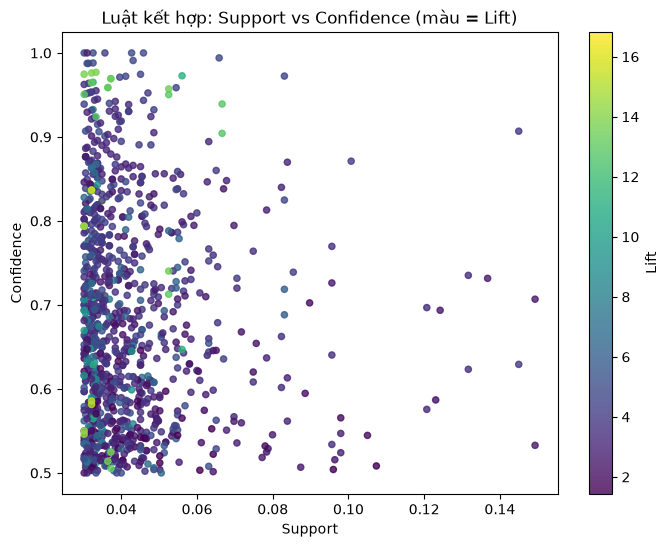

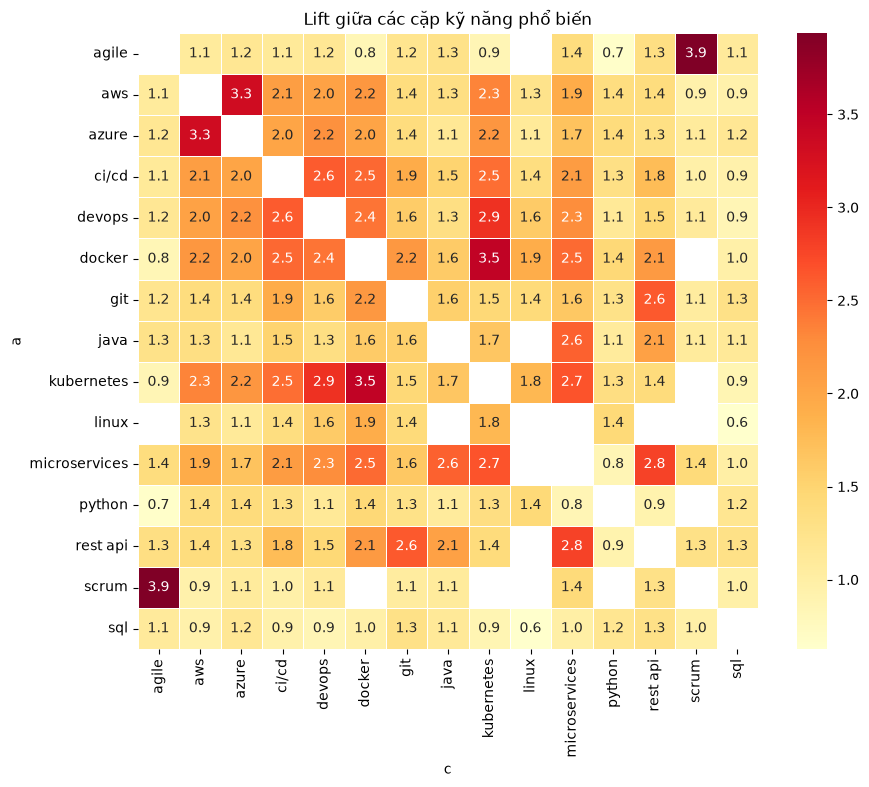

In [13]:
plt.figure(figsize=(8, 6))
sc = plt.scatter(rules_f['support'], rules_f['confidence'], c=rules_f['lift'], cmap='viridis', s=20, alpha=0.8)
plt.colorbar(sc, label='Lift')
plt.xlabel('Support'); plt.ylabel('Confidence')
plt.title('Luật kết hợp: Support vs Confidence (màu = Lift)')
plt.show()

top = onehot.mean().sort_values(ascending=False).head(15).index.tolist()
pairs = rules[(rules['antecedents'].apply(len) == 1) & (rules['consequents'].apply(len) == 1)].copy()
pairs['a'] = pairs['antecedents'].apply(lambda x: next(iter(x)))
pairs['c'] = pairs['consequents'].apply(lambda x: next(iter(x)))
hm = pairs[pairs['a'].isin(top) & pairs['c'].isin(top)].pivot(index='a', columns='c', values='lift')

plt.figure(figsize=(10, 8))
sns.heatmap(hm, annot=True, fmt='.1f', cmap='YlOrRd', linewidths=0.5)
plt.title('Lift giữa các cặp kỹ năng phổ biến')
plt.show()

###  Phân tích Bước 2.5.12: Trực quan hóa

**Vì sao làm bước này?**
Bảng số liệu cho chi tiết nhưng không cho thấy *cấu trúc tổng thể*. Hai biểu đồ bổ sung cho nhau:

**Biểu đồ 1: Scatter Support × Confidence (màu = Lift)**, vẽ trên 1.070 luật đã lọc
- Mỗi chấm là một luật. Trục ngang là mức phổ biến, trục dọc là độ chắc chắn, màu sắc thể hiện độ gắn kết (lift).
- **Cách đọc:** Luật lý tưởng nằm ở **góc trên bên phải** (phổ biến, chắc chắn, gắn kết mạnh). Dữ liệu cho thấy phần lớn luật tập trung ở support thấp (khoảng 3–6%), còn các luật lift cao (màu sáng) thường nằm ở những tổ hợp ngách. Luật mạnh thường là luật chuyên biệt, không phải luật phổ biến.

**Biểu đồ 2: Heatmap Lift giữa các cặp trong 15 kỹ năng phổ biến nhất**
- Mỗi ô là lift của luật một-một `A ⇒ B`. Ô càng đậm, hai kỹ năng càng gắn kết.
- **Cách đọc:** Các khối ô đậm cho thấy cụm kỹ năng đi theo bộ (web front-end, Java/Spring, Docker/Kubernetes/AWS). Ô trống nghĩa là cặp đó không có luật (không đạt support).

---

##  KẾT LUẬN CHUNG

**Quá trình đã làm:** từ 3.135 tin tuyển dụng → 2.552 giỏ kỹ năng → 769 tập phổ biến → 3.472 luật thô → **1.070 luật chất lượng**.

**Phát hiện chính:**
1. **Các cụm kỹ năng rõ rệt:** web front-end (HTML/CSS/JavaScript/React), mobile (Android + iOS), Java backend (Spring), DevOps/Cloud (Docker, Kubernetes, AWS) và Data/ML (ML ⇒ Python).
2. **Quan hệ có hướng:** Kubernetes ⇒ Docker mạnh hơn Docker ⇒ Kubernetes, vì Docker là kỹ năng nền.
3. **Phổ biến ≠ gắn kết:** Python và SQL xuất hiện nhiều nhất nhưng lift chỉ 1,19, tức đi cùng nhau chủ yếu do cùng phổ biến.
4. **Cần diễn giải thận trọng:** nhiều luật confidence 100% chỉ phản ánh quan hệ kỹ thuật hiển nhiên (framework ⇒ ngôn ngữ).

**Hạn chế:**
- Dữ liệu chỉ từ một nguồn (ITviec) và một thời điểm, nên kết quả có thể không đại diện toàn thị trường.
- Kỹ năng đi cùng nhau chưa chắc có quan hệ nhân quả; luật kết hợp chỉ mô tả sự đồng xuất hiện.
- Ngưỡng `MIN_COUNT` và `MIN_SUP` là chủ quan, thay đổi sẽ thay đổi tập luật.

**Hướng phát triển:**
- Gợi ý lộ trình học: "đã biết A, nên học B tiếp theo" dựa trên luật có lift và confidence cao.
- Phân cụm công việc theo bộ kỹ năng (dùng thêm `text_for_tfidf`).
- Kết hợp với lương và kinh nghiệm (`Luong_TB`, `experience_group`) để xem cụm kỹ năng nào được trả cao hơn.